Starter med å sette opp. importere og definere

extra

In [ ]:
%pip

Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
import os
from sklearn.model_selection import train_test_split


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
#from torchvision.io import decode_image, ImageReadMode
from PIL import Image  # torchvision fra AMD (ROCm) mangler JPEG-støtte, så bilder leses med PIL

DATA

In [3]:
NB_DIR = Path.cwd()       # Set NB_DIR to be the current working directory
DATA = NB_DIR.parent/'data' 


In [4]:
FILE = DATA / 'flowers'

In [5]:
LABEL = DATA / 'labels.csv'

In [6]:
# klasser og antall
from collections import Counter

root = FILE  # change to your unzipped folder name
for dirpath, dirs, files in os.walk(root):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        print(f"{os.path.basename(dirpath)}: {len(imgs)} images")

astilbe: 737 images
bellflower: 873 images
black_eyed_susan: 1000 images
calendula: 978 images
california_poppy: 1022 images
carnation: 923 images
common_daisy: 980 images
coreopsis: 1047 images
daffodil: 970 images
dandelion: 1052 images
iris: 1054 images
lavender: 500 images
lotus: 500 images
magnolia: 1048 images
orchid: 489 images
rose: 999 images
sunflower: 1027 images
tulip: 1048 images
water_lily: 982 images


In [7]:
#test
x = torch.rand(5, 3)
print(x)


tensor([[0.7598, 0.4280, 0.2945],
        [0.2674, 0.7415, 0.5463],
        [0.9245, 0.6711, 0.6472],
        [0.8407, 0.0604, 0.0381],
        [0.7996, 0.8232, 0.2775]])


INIT data


In [8]:
#lage labels / definerer klassene og lage splits.

classes = sorted(d.name for d in FILE.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

rows = []
for c in classes:
    for f in (FILE / c).iterdir():
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            rows.append({"path": f"{c}/{f.name}", "label": class_to_idx[c]})
df = pd.DataFrame(rows)

# 70/15/15, stratifisert
train, tmp = train_test_split(df, test_size=0.3, stratify=df.label, random_state=42)
val, test  = train_test_split(tmp, test_size=0.5, stratify=tmp.label, random_state=42)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

df.to_csv(DATA / "labels.csv", index=False)
print(df.split.value_counts(), "\n", classes)

split
train    12060
test      2585
val       2584
Name: count, dtype: int64 
 ['astilbe', 'bellflower', 'black_eyed_susan', 'calendula', 'california_poppy', 'carnation', 'common_daisy', 'coreopsis', 'daffodil', 'dandelion', 'iris', 'lavender', 'lotus', 'magnolia', 'orchid', 'rose', 'sunflower', 'tulip', 'water_lily']


In [9]:
# INIT data

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, split, transform=None, target_transform=None):
        df = pd.read_csv(annotations_file)
        self.img_labels = df[df["split"] == split].reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = v2.functional.pil_to_tensor(Image.open(img_path).convert("RGB"))  # uint8 [3, H, W]
        label = int(self.img_labels.iloc[idx, 1])
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label


In [10]:
# augmentering. endring av input for å motvirke overfitting

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.7, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),   # uint8 0–255 -> float 0–1
    v2.Normalize(mean, std),
])
eval_tf = v2.Compose([
    v2.Resize(256, antialias=True),
    v2.CenterCrop(224),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std),
])


In [11]:
training_data = CustomImageDataset(LABEL, FILE, "train", train_tf)
val_data      = CustomImageDataset(LABEL, FILE, "val",   eval_tf)
test_data     = CustomImageDataset(LABEL, FILE, "test",  eval_tf)

In [12]:
# DATA loader

batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
val_dataloader   = DataLoader(val_data,      batch_size=batch_size)
test_dataloader  = DataLoader(test_data,     batch_size=batch_size)

X, y = next(iter(train_dataloader))
print(X.shape, X.dtype, y[:8])  # torch.Size([32, 3, 224, 224]) torch.float32

torch.Size([64, 3, 224, 224]) torch.float32 tensor([13,  1, 16, 10,  5, 17, 18, 16])


Feature batch shape: torch.Size([64, 3, 224, 224])
Labels batch shape: torch.Size([64])


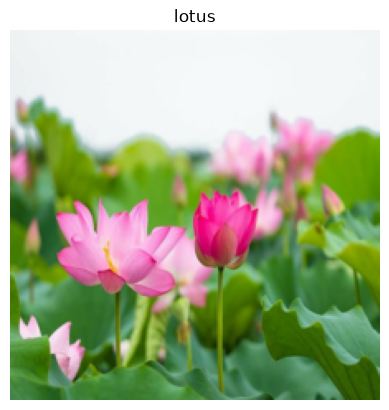

Label: 12 (lotus)


In [33]:
#display

# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

img = train_features[0]                                            # [3, 224, 224]
img = img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)  # angre Normalize
img = img.permute(1, 2, 0).clamp(0, 1)                             # -> [224, 224, 3]
label = train_labels[0].item()

plt.imshow(img)
plt.title(classes[label])
plt.axis("off")
plt.show()
print(f"Label: {label} ({classes[label]})")

